In [120]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load and Clean Excel Sheets as DFs:

In [121]:
CO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='CO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
SO2_df = pd.read_excel("Emissions2024.xlsx", sheet_name='SO2', header=1, skipfooter=2).query("`Plant Code`!=99999")
NOx_df = pd.read_excel("Emissions2024.xlsx", sheet_name='NOx', header=1, skipfooter=2).query("`Plant Code`!=99999")

# Cast SO2 and NOx Emissions as a Float:

In [122]:
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].replace(' ', 0)
SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'] = SO2_df['EIA Model Estimates of SO2 Emissions (Tons)'].astype('float')
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].replace(' ', 0)
NOx_df['EIA Model Estimates of NOx Emissions (Tons)'] = NOx_df['EIA Model Estimates of NOx Emissions (Tons)'].astype('float')

# Impute values for Alaska/Hawaii in NERC and balancing authority

In [123]:
CO2_df['NERC Region'].value_counts()

NERC Region
SERC    1109
RFC      922
WECC     887
MRO      880
NPCC     584
TRE      400
Name: count, dtype: int64

# Replace prime mover values with something interpretable:

In [124]:
pm_replace_map = {'IC': 'Internal Combustion Engine',
'CA': 'Combined Cycle Steam Part',
'CT': 'Combined Cycle Combustion Turbine Part',
'ST': 'Steam Turbine',
'GT': 'Combustion (Gas) Turbine',
'CS': 'Combined Cycle Single Shaft',
'CE': 'Energy Storage, Compressed Air',
'OT': 'Other',
'FC': 'Fuel Cell'
}
 
CO2_df['Prime Mover Name'] = CO2_df['Prime Mover'].replace(pm_replace_map)
SO2_df['Prime Mover Name'] = SO2_df['Prime Mover'].replace(pm_replace_map)
NOx_df['Prime Mover Name'] = NOx_df['Prime Mover'].replace(pm_replace_map)

In [125]:
CO2_df

,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Fuel Code,Aggregated Fuel Group,Generation (kWh),Useful Thermal Output (MMBtu),...,\n Fuel Consumption for Useful Thermal Output (MMBtu),Quantity of Fuel Consumed,Fuel Units,Tons of CO2 Emissions,Metric Tonnes of CO2 Emissions,NERC Region,Balancing Authority Code,Balancing Authority Name,EIA Balancing Authority Region,Prime Mover Name
0,1,Sand Point,AK,ELECTRIC POWER,1,IC,DFO,PET,3616000,0,...,0,6307,Barrels,3196,2899,NaN,NaN,Balancing Authority Not Reported,Alaska,Internal Combustion Engine
1,3,Barry,AL,ELECTRIC POWER,1,CA,NG,GAS,4519611000,0,...,0,3171351,Mcf,188829,171303,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Combined Cycle Steam Part
2,3,Barry,AL,ELECTRIC POWER,1,CT,NG,GAS,8653458000,0,...,0,84516338,Mcf,5032786,4565672,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Combined Cycle Combustion Turbine Part
3,3,Barry,AL,ELECTRIC POWER,1,ST,BIT,COAL,697528563,0,...,0,395622,Tons,802806,728294,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Steam Turbine
4,3,Barry,AL,ELECTRIC POWER,1,ST,NG,GAS,185271437,0,...,0,2630417,Mcf,156709,142164,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Steam Turbine
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4946,68733,HEB00798,TX,ELECTRIC POWER,2,IC,NG,GAS,136000,0,...,0,1911,Mcf,134,121,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",Internal Combustion Engine
4947,68734,HEB00801,TX,ELECTRIC POWER,2,IC,NG,GAS,146000,0,...,0,1815,Mcf,127,115,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",Internal Combustion Engine
4948,68735,HEBTEMDistCenter1B,TX,ELECTRIC POWER,2,IC,NG,GAS,309000,0,...,0,4387,Mcf,307,279,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",Internal Combustion Engine
4949,68736,HEBTEMDistCenter2A,TX,ELECTRIC POWER,2,IC,NG,GAS,309000,0,...,0,4387,Mcf,307,279,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",Internal Combustion Engine


# EDA:

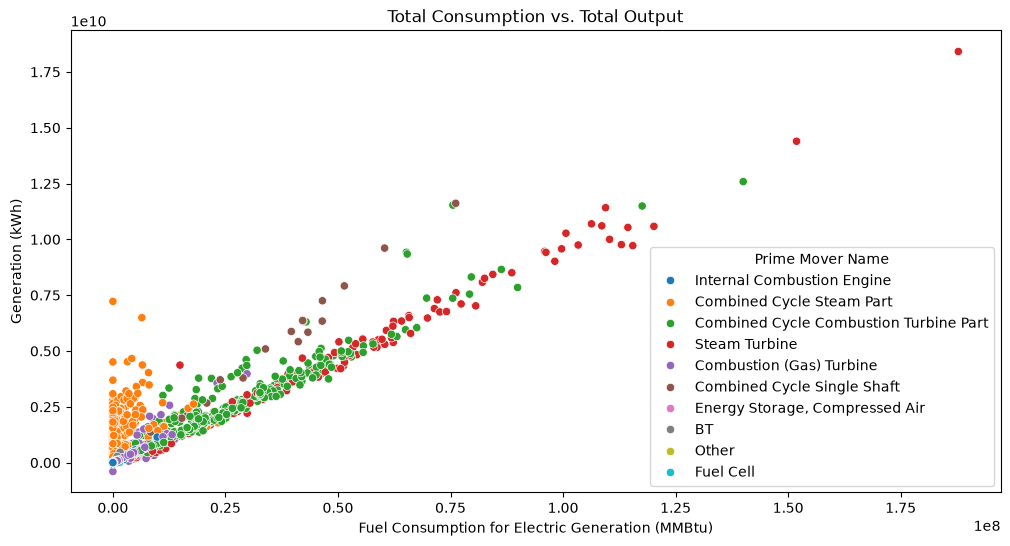

In [126]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=CO2_df, x="Fuel Consumption for Electric Generation (MMBtu)", y="Generation (kWh)", hue='Prime Mover Name')

plt.title("Total Consumption vs. Total Output")
plt.show()

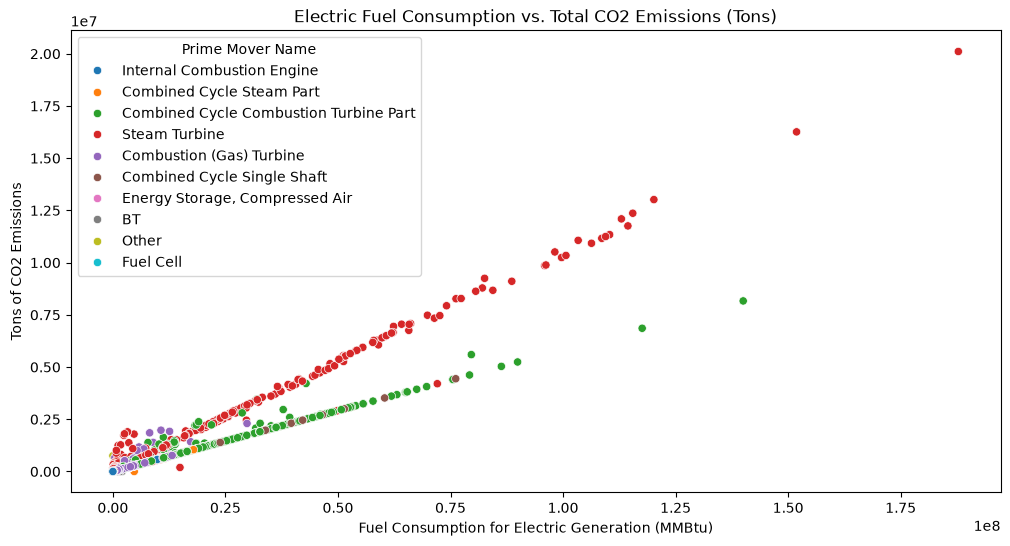

In [127]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=CO2_df, x="Fuel Consumption for Electric Generation (MMBtu)", y="Tons of CO2 Emissions", hue='Prime Mover Name')

plt.title("Electric Fuel Consumption vs. Total CO2 Emissions (Tons)")
plt.show()

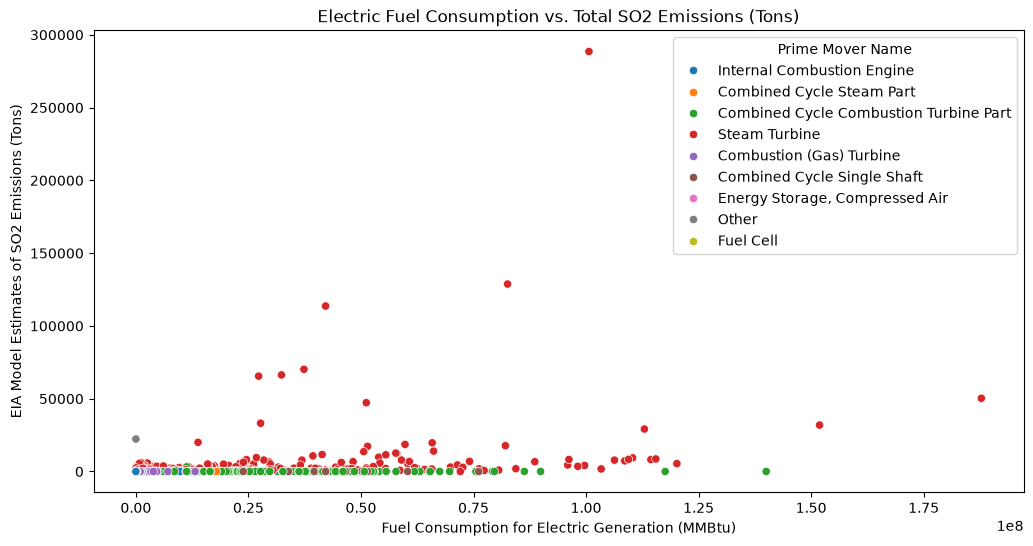

In [128]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=SO2_df, x="Fuel Consumption for Electric Generation (MMBtu)", y="EIA Model Estimates of SO2 Emissions (Tons)", hue='Prime Mover Name')

plt.title("Electric Fuel Consumption vs. Total SO2 Emissions (Tons)")
plt.show()

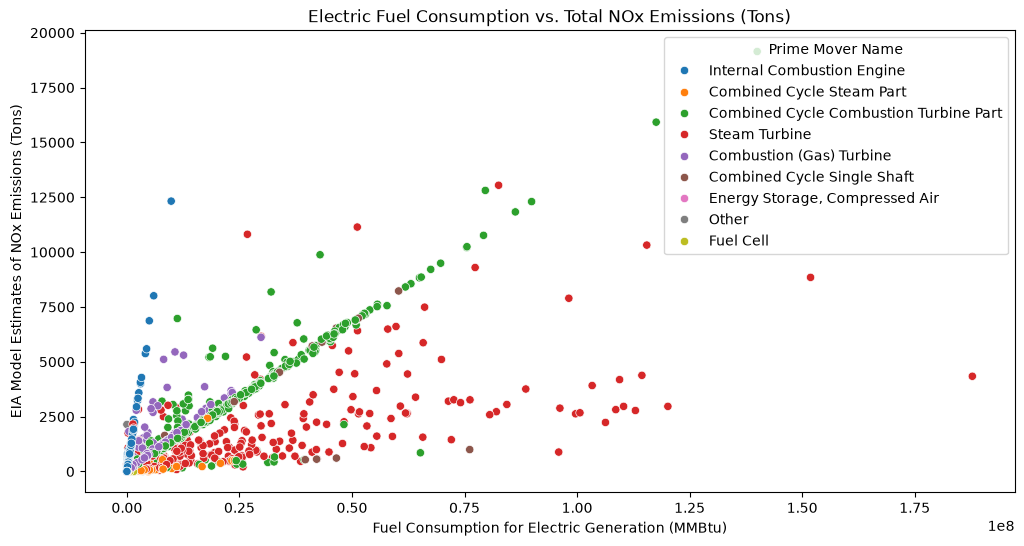

In [129]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(data=NOx_df, x="Fuel Consumption for Electric Generation (MMBtu)", y="EIA Model Estimates of NOx Emissions (Tons)", hue='Prime Mover Name')

plt.title("Electric Fuel Consumption vs. Total NOx Emissions (Tons)")
plt.show()

# Create a unique key column for each DF:

In [130]:
CO2_df['Plant Code'] = CO2_df['Plant Code'].astype('str')
CO2_df['Sector Code'] = CO2_df['Sector Code'].astype('str')
CO2_df['Plant_PM_Fuel'] = CO2_df['Plant Code'] + '_' + CO2_df['Sector Code'] + '_' + CO2_df['Prime Mover'] + '_' + CO2_df['Fuel Code']

In [131]:
SO2_df['Plant Code'] = SO2_df['Plant Code'].astype('str')
SO2_df['Sector Code'] = SO2_df['Sector Code'].astype('str')
SO2_df['Plant_PM_Fuel'] = SO2_df['Plant Code'] + '_' + SO2_df['Sector Code'] + '_' + SO2_df['Prime Mover'] + '_' + SO2_df['Fuel Code']

In [132]:
NOx_df['Plant Code'] = NOx_df['Plant Code'].astype('str')
NOx_df['Sector Code'] = NOx_df['Sector Code'].astype('str')
NOx_df['Plant_PM_Fuel'] = NOx_df['Plant Code'] + '_' + NOx_df['Sector Code'] + '_' + NOx_df['Prime Mover'] + '_' + NOx_df['Fuel Code']

# Inner Merge Emissions Outputs into one DF:

In [133]:
result = pd.merge(
    CO2_df, 
    SO2_df[['Plant_PM_Fuel', 'EIA Model Estimates of SO2 Emissions (Tons)']], 
    on='Plant_PM_Fuel', 
    how='inner'
)

In [134]:
total_pollution_df = pd.merge(
    result, 
    NOx_df[['Plant_PM_Fuel', 'EIA Model Estimates of NOx Emissions (Tons)']], 
    on='Plant_PM_Fuel', 
    how='inner'
)

In [135]:
total_pollution_df.head()

,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Fuel Code,Aggregated Fuel Group,Generation (kWh),Useful Thermal Output (MMBtu),...,Tons of CO2 Emissions,Metric Tonnes of CO2 Emissions,NERC Region,Balancing Authority Code,Balancing Authority Name,EIA Balancing Authority Region,Prime Mover Name,Plant_PM_Fuel,EIA Model Estimates of SO2 Emissions (Tons),EIA Model Estimates of NOx Emissions (Tons)
0,1,Sand Point,AK,ELECTRIC POWER,1,IC,DFO,PET,3616000,0,...,3196,2899,NaN,NaN,Balancing Authority Not Reported,Alaska,Internal Combustion Engine,1_1_IC_DFO,5.006497,58.779979
1,3,Barry,AL,ELECTRIC POWER,1,CA,NG,GAS,4519611000,0,...,188829,171303,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Combined Cycle Steam Part,3_1_CA_NG,0.951405,354.670970
2,3,Barry,AL,ELECTRIC POWER,1,CT,NG,GAS,8653458000,0,...,5032786,4565672,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Combined Cycle Combustion Turbine Part,3_1_CT_NG,25.354901,11832.287000
3,3,Barry,AL,ELECTRIC POWER,1,ST,BIT,COAL,697528563,0,...,802806,728294,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Steam Turbine,3_1_ST_BIT,273.692210,217.592100
4,3,Barry,AL,ELECTRIC POWER,1,ST,NG,GAS,185271437,0,...,156709,142164,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,Steam Turbine,3_1_ST_NG,0.672110,67.171504


In [136]:
nan_cols = total_pollution_df.columns[total_pollution_df.isna().any()].tolist()
print(nan_cols)

['NERC Region', 'Balancing Authority Code']


In [137]:
total_pollution_df['Fuel Consumption for Useful Thermal Output (MMBtu)'] = total_pollution_df['\n Fuel Consumption for Useful Thermal Output (MMBtu)']

In [138]:
total_pollution_df.columns

Index(['Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Useful Thermal Output (MMBtu)', 'Total Fuel Consumption (MMBtu)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       '\n Fuel Consumption for Useful Thermal Output (MMBtu)',
       'Quantity of Fuel Consumed', 'Fuel Units', 'Tons of CO2 Emissions',
       'Metric Tonnes of CO2 Emissions', 'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region', 'Prime Mover Name', 'Plant_PM_Fuel',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of NOx Emissions (Tons)',
       'Fuel Consumption for Useful Thermal Output (MMBtu)'],
      dtype='str')

In [141]:
clean_cols = ['Plant_PM_Fuel', 'Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Prime Mover Name', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region',
       'Tons of CO2 Emissions',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of NOx Emissions (Tons)']

In [142]:
tp_clean = total_pollution_df[clean_cols]
tp_clean

,Plant_PM_Fuel,Plant Code,Plant Name,State,Sector Group,Sector Code,Prime Mover,Prime Mover Name,Fuel Code,Aggregated Fuel Group,Generation (kWh),Fuel Consumption for Electric Generation (MMBtu),NERC Region,Balancing Authority Code,Balancing Authority Name,EIA Balancing Authority Region,Tons of CO2 Emissions,EIA Model Estimates of SO2 Emissions (Tons),EIA Model Estimates of NOx Emissions (Tons)
0,1_1_IC_DFO,1,Sand Point,AK,ELECTRIC POWER,1,IC,Internal Combustion Engine,DFO,PET,3616000,39104,NaN,NaN,Balancing Authority Not Reported,Alaska,3196,5.006497,58.779979
1,3_1_CA_NG,3,Barry,AL,ELECTRIC POWER,1,CA,Combined Cycle Steam Part,NG,GAS,4519611000,3237638,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,188829,0.951405,354.670970
2,3_1_CT_NG,3,Barry,AL,ELECTRIC POWER,1,CT,Combined Cycle Combustion Turbine Part,NG,GAS,8653458000,86291289,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,5032786,25.354901,11832.287000
3,3_1_ST_BIT,3,Barry,AL,ELECTRIC POWER,1,ST,Steam Turbine,BIT,COAL,697528563,7810960,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,802806,273.692210,217.592100
4,3_1_ST_NG,3,Barry,AL,ELECTRIC POWER,1,ST,Steam Turbine,NG,GAS,185271437,2686899,SERC,SOCO,"Southern Company Services, Inc. - Trans",Southeast,156709,0.672110,67.171504
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4877,68733_2_IC_NG,68733,HEB00798,TX,ELECTRIC POWER,2,IC,Internal Combustion Engine,NG,GAS,136000,2294,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",134,0.000573,2.644824
4878,68734_2_IC_NG,68734,HEB00801,TX,ELECTRIC POWER,2,IC,Internal Combustion Engine,NG,GAS,146000,2178,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",127,0.000544,2.511960
4879,68735_2_IC_NG,68735,HEBTEMDistCenter1B,TX,ELECTRIC POWER,2,IC,Internal Combustion Engine,NG,GAS,309000,5264,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",307,0.001316,6.071608
4880,68736_2_IC_NG,68736,HEBTEMDistCenter2A,TX,ELECTRIC POWER,2,IC,Internal Combustion Engine,NG,GAS,309000,5264,TRE,ERCO,"Electric Reliability Council of Texas, Inc.","Electric Reliability Council of Texas, Inc.",307,0.001316,6.071608


In [ ]:
model_cols = ['Plant_PM_Fuel', 'Plant Code', 'Plant Name', 'State', 'Sector Group', 'Sector Code',
       'Prime Mover', 'Prime Mover Name', 'Fuel Code', 'Aggregated Fuel Group', 'Generation (kWh)',
       'Fuel Consumption for Electric Generation (MMBtu)',
       'NERC Region',
       'Balancing Authority Code', 'Balancing Authority Name',
       'EIA Balancing Authority Region',
       'Tons of CO2 Emissions',
       'EIA Model Estimates of SO2 Emissions (Tons)',
       'EIA Model Estimates of NOx Emissions (Tons)']